## **UTS GSD - 20/10/2026**

Nama    : Fadhil Muhamad

NIM     : 23031554090

Matkul  : Graf Sains Data

# **1. Tugas Pendahuluan**


## *1.1 Persiapan dan Perkenalan Lingkungan*

In [ ]:
import neo4j
import pandas as pd
import networkx as nx
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt

print("Neo4j Driver :", neo4j.__version__)
print("Pandas       :", pd.__version__)
print("NetworkX     :", nx.__version__)
print("NumPy        :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

from neo4j import GraphDatabase, RoutingControl

Neo4j Driver : 6.4.0
Pandas       : 2.2.3
NetworkX     : 3.4.2
NumPy        : 1.26.4
Scikit-learn : 1.7.0
Semua library utama berhasil diimpor!


## *1.2 Mempelajari Penggunaan Driver Neo4J*

In [ ]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "password")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Berhasil terhubung ke Neo4j!")

Berhasil terhubung ke Neo4j!


In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print_friends(driver, "Arthur")

### *Pertanyaan Pendahuluan (Checkpoint)*

---

#### 1. Apa nama database yang digunakan pada tutorial ini?

**Jawaban:** `neo4j`

**Penjelasan:**
Ditunjukkan oleh parameter `database_="neo4j"` pada pemanggilan fungsi `driver.execute_query()` di Python Driver.

---

#### 2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!

**Jawaban:**
Selain menentukan database melalui parameter `database_` pada Python Driver, database Neo4j dapat diakses menggunakan beberapa cara berikut:

| Cara | Contoh | Fungsi |
| :--- | :--- | :--- |
| **Python Driver** | `driver.execute_query(query, database_="neo4j")` | Menentukan database tujuan dari Python. |
| **Klausa Cypher USE** | `USE neo4j MATCH (n) RETURN count(n)` | Memilih database tujuan untuk query Cypher. |
| **Neo4j Query / cypher-shell** | `:use neo4j` | Memilih database aktif pada antarmuka yang mendukung perintah tersebut. |
| **Perintah Administrasi** | `SHOW DATABASES` | Melihat database yang tersedia dalam instance. |

---

#### 3. Apa jenis graf pertemanan yang telah dibuat di sini?

**Jawaban:**
Graf berarah (**directed graph**) dengan label node `Person` dan relasi `KNOWS`.

**Penjelasan:**
Berdasarkan kode tutorial:

```cypher
MERGE (a:Person {name: $name})
MERGE (friend:Person {name: $friend_name})
MERGE (a)-[:KNOWS]->(friend)

## *1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J*

# **2. Soal UTS**


## *2.1 Wrangling dan EDA*

In [ ]:
from neo4j import GraphDatabase
from pathlib import Path
import pandas as pd
import numpy as np

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "password")
DATABASE = "neo4j"

CSV_PATH = Path("events_P1-P2.csv")
BATCH_SIZE = 5000

def create_constraints(session):
    queries = [
        """
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
        """,
        """
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
        """
    ]

    for query in queries:
        session.run(query)

def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp,
            fold: row.fold
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp,
            fold: row.fold
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid,
            fold: row.fold
        }]->(i)
    }
    """
    tx.run(query, batch=batch).consume()

if not CSV_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_PATH}")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil.")

Koneksi Neo4j berhasil.


In [ ]:
from tqdm.auto import tqdm

total_rows = 610393
total_chunks = (total_rows + BATCH_SIZE - 1) // BATCH_SIZE

chunks = pd.read_csv(
    CSV_PATH,
    chunksize=BATCH_SIZE
)

total_imported = 0

with driver.session(database=DATABASE) as session:
    create_constraints(session)

    for chunk in tqdm(
        chunks,
        total=(920030 + BATCH_SIZE - 1) // BATCH_SIZE,
        desc="Mengimpor P1"
    ):
        # Jangan masukkan data testing ke graf training
        chunk = chunk.loc[
            chunk["fold"] == "P1_training"
        ].copy()

        if chunk.empty:
            continue

        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )

        # Pastikan tipe data sesuai untuk Neo4j
        chunk["timestamp"] = chunk["timestamp"].astype("int64")
        chunk["visitorid"] = chunk["visitorid"].astype("int64")
        chunk["itemid"] = chunk["itemid"].astype("int64")

        records = chunk.to_dict(orient="records")

        session.execute_write(import_batch, records)
        total_imported += len(records)

print(f"Total interaksi P1 diproses: {total_imported:,}")

Mengimpor P1:   0%|          | 0/185 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {\n            timestamp: row.timestamp,\n            fold: row.fold\n        

Total interaksi P1 diproses: 610,393


#### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi.
#### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!
- Batas filter menentukan tanggal yang boleh masuk ke periode: P1 adalah 1–30 Juni 2015, sedangkan P2 adalah 1–14 Juli 2015.

| GForm | Nilai UNIX timestamp (ms) |
| :--- | :--- |
| Periode dataset P1 mulai | 1433116801707 |
| Periode dataset P1 selesai | 1435708799292 |
| Periode dataset P2 mulai (testing) | 1435708806967 |
| Periode dataset P2 selesai (testing) | 1436918396104 |

Saya jalankan pemilihan periode melalui data_event.csv

#### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!
#### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!
#### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!
#### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!
#### 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python


(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!
#### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [ ]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.fold = 'P1_training'
        RETURN
            type(r) AS relationship_type,
            count(r) AS total_relationships,
            count(DISTINCT v) AS visitors,
            count(DISTINCT i) AS items
        ORDER BY relationship_type
    """)

    for record in result:
        print(dict(record))

{'relationship_type': 'ADDED_TO_CART', 'total_relationships': 15095, 'visitors': 8595, 'items': 8144}
{'relationship_type': 'BOUGHT', 'total_relationships': 5043, 'visitors': 2728, 'items': 3589}
{'relationship_type': 'VIEWED', 'total_relationships': 590255, 'visitors': 313218, 'items': 117153}


In [ ]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (v:Visitor)
        RETURN count(v) AS total_visitors
    """)
    print("Total simpul Visitor:", result.single()["total_visitors"])

    result = session.run("""
        MATCH (i:Item)
        RETURN count(i) AS total_items
    """)
    print("Total simpul Item:", result.single()["total_items"])

Total simpul Visitor: 313832
Total simpul Item: 117317


In [ ]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->()
        WHERE r.fold = 'P1_training'
        RETURN count(DISTINCT v) AS total_visitor
    """)
    print("Visitor P1:", result.single()["total_visitor"])

    result = session.run("""
        MATCH ()-[r]->(i:Item)
        WHERE r.fold = 'P1_training'
        RETURN count(DISTINCT i) AS total_item
    """)
    print("Item P1:", result.single()["total_item"])

Visitor P1: 313832
Item P1: 117317


In [ ]:
with driver.session(database=DATABASE) as session:
    queries = {
        "Relasi per fold": """
            MATCH ()-[r]->()
            RETURN r.fold AS fold, count(r) AS total
            ORDER BY fold
        """,
        "Visitor terhubung ke relasi P1": """
            MATCH (v:Visitor)-[r]->()
            WHERE r.fold = 'P1_training'
            RETURN count(DISTINCT v) AS total
        """,
        "Item terhubung ke relasi P1": """
            MATCH ()-[r]->(i:Item)
            WHERE r.fold = 'P1_training'
            RETURN count(DISTINCT i) AS total
        """,
        "Visitor dengan relasi apa pun": """
            MATCH (v:Visitor)-[r]->()
            RETURN count(DISTINCT v) AS total
        """,
        "Item dengan relasi apa pun": """
            MATCH ()-[r]->(i:Item)
            RETURN count(DISTINCT i) AS total
        """
    }

    for title, query in queries.items():
        print(f"\n{title}")
        for record in session.run(query):
            print(dict(record))


Relasi per fold
{'fold': 'P1_training', 'total': 610393}

Visitor terhubung ke relasi P1
{'total': 313832}

Item terhubung ke relasi P1
{'total': 117317}

Visitor dengan relasi apa pun
{'total': 313832}

Item dengan relasi apa pun
{'total': 117317}


In [ ]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.fold = 'P1_training'
        RETURN
            type(r) AS relationship_type,
            count(r) AS total_relationships,
            count(DISTINCT v) AS unique_visitors,
            count(DISTINCT i) AS unique_items
        ORDER BY relationship_type
    """)

    composition = pd.DataFrame([dict(record) for record in result])

display(composition)

,relationship_type,total_relationships,unique_visitors,unique_items
0,ADDED_TO_CART,15095,8595,8144
1,BOUGHT,5043,2728,3589
2,VIEWED,590255,313218,117153


In [ ]:
# PEMERIKSAAN AWAL GRAF TRAINING
# Aman dijalankan berulang kali: hanya menjalankan query baca.

with driver.session(database=DATABASE) as session:
    checks = {
        "Jumlah relasi training": """
            MATCH ()-[r]->()
            WHERE r.fold = 'P1_training'
            RETURN count(r) AS hasil
        """,
        "Jumlah visitor unik training": """
            MATCH (v:Visitor)-[r]->()
            WHERE r.fold = 'P1_training'
            RETURN count(DISTINCT v) AS hasil
        """,
        "Jumlah item unik training": """
            MATCH ()-[r]->(i:Item)
            WHERE r.fold = 'P1_training'
            RETURN count(DISTINCT i) AS hasil
        """,
        "Relasi tanpa fold": """
            MATCH ()-[r]->()
            WHERE r.fold IS NULL
            RETURN count(r) AS hasil
        """
    }

    for nama, query in checks.items():
        record = session.run(query).single()
        print(f"{nama}: {record['hasil']:,}")

Jumlah relasi training: 610,393
Jumlah visitor unik training: 313,832
Jumlah item unik training: 117,317
Relasi tanpa fold: 0


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# 1. Pastikan file sumber tersedia
CSV_PATH = Path("events_P1-P2.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {CSV_PATH.resolve()}\n"
        "Periksa lokasi file sebelum melanjutkan."
    )

# 2. Baca kolom yang diperlukan saja
df = pd.read_csv(
    CSV_PATH,
    usecols=["visitorid", "itemid", "fold"]
)

# 3. Ambil data training saja
df_p1 = df.loc[
    df["fold"].eq("P1_training"),
    ["visitorid", "itemid"]
].drop_duplicates()

# 4. Petakan ID asli ke indeks matriks
user_ids, user_idx = np.unique(
    df_p1["visitorid"].to_numpy(),
    return_inverse=True
)

item_ids, item_idx = np.unique(
    df_p1["itemid"].to_numpy(),
    return_inverse=True
)

# 5. Bangun User–Item VSM biner dalam format sparse
X_ui = csr_matrix(
    (
        np.ones(len(df_p1), dtype=np.float32),
        (user_idx, item_idx)
    ),
    shape=(len(user_ids), len(item_ids))
)

# 6. Validasi hasil
n_users, n_items = X_ui.shape
n_pairs = X_ui.nnz
total_pairs = n_users * n_items
sparsity = 1 - (n_pairs / total_pairs)
memory_mb = (
    X_ui.data.nbytes
    + X_ui.indices.nbytes
    + X_ui.indptr.nbytes
) / (1024 ** 2)

print("=== HASIL USER–ITEM VSM ===")
print(f"Jumlah visitor       : {n_users:,}")
print(f"Jumlah item          : {n_items:,}")
print(f"Pasangan unik        : {n_pairs:,}")
print(f"Ukuran matriks       : {n_users:,} × {n_items:,}")
print(f"Sparsity             : {sparsity:.6%}")
print(f"Memori matriks       : {memory_mb:.2f} MB")

print("\n=== VALIDASI ===")
print(
    "Visitor sesuai Neo4j :",
    n_users == 313_832
)
print(
    "Item sesuai Neo4j    :",
    n_items == 117_317
)
print(
    "Nilai matriks hanya 0/1:",
    X_ui.data.size == X_ui.nnz
    and np.all(X_ui.data == 1)
)

=== HASIL USER–ITEM VSM ===
Jumlah visitor       : 313,832
Jumlah item          : 117,317
Pasangan unik        : 471,258
Ukuran matriks       : 313,832 × 117,317
Sparsity             : 99.998720%
Memori matriks       : 4.79 MB

=== VALIDASI ===
Visitor sesuai Neo4j : True
Item sesuai Neo4j    : True
Nilai matriks hanya 0/1: True


In [ ]:
# PERBANDINGAN AWAL PROYEKSI USER–USER DAN ITEM–ITEM
# Aman dijalankan berulang kali.

# Proyeksi user: setiap baris mewakili satu visitor
X_uu = X_ui

# Proyeksi item: setiap baris mewakili satu item
X_iu = X_ui.T.tocsr()

def ringkasan_matriks(nama, X):
    jumlah_per_baris = np.diff(X.indptr)

    print(f"\n{nama}")
    print(f"  Bentuk matriks       : {X.shape[0]:,} × {X.shape[1]:,}")
    print(f"  Jumlah nilai nonzero : {X.nnz:,}")
    print(f"  Rata-rata nonzero/baris: {jumlah_per_baris.mean():.2f}")
    print(f"  Median nonzero/baris : {np.median(jumlah_per_baris):.0f}")
    print(f"  Maksimum nonzero/baris: {jumlah_per_baris.max():,}")

ringkasan_matriks("USER–ITEM (untuk kemiripan antar-user)", X_uu)
ringkasan_matriks("ITEM–USER (untuk kemiripan antar-item)", X_iu)

print("\n=== PERBANDINGAN JUMLAH OBJEK ===")
print(f"Objek pada proyeksi User–User: {X_uu.shape[0]:,}")
print(f"Objek pada proyeksi Item–Item: {X_iu.shape[0]:,}")
print(
    "Rasio jumlah objek user terhadap item:",
    f"{X_uu.shape[0] / X_iu.shape[0]:.2f} kali"
)


USER–ITEM (untuk kemiripan antar-user)
  Bentuk matriks       : 313,832 × 117,317
  Jumlah nilai nonzero : 471,258
  Rata-rata nonzero/baris: 1.50
  Median nonzero/baris : 1
  Maksimum nonzero/baris: 1,031

ITEM–USER (untuk kemiripan antar-item)
  Bentuk matriks       : 117,317 × 313,832
  Jumlah nilai nonzero : 471,258
  Rata-rata nonzero/baris: 4.02
  Median nonzero/baris : 2
  Maksimum nonzero/baris: 1,022

=== PERBANDINGAN JUMLAH OBJEK ===
Objek pada proyeksi User–User: 313,832
Objek pada proyeksi Item–Item: 117,317
Rasio jumlah objek user terhadap item: 2.68 kali


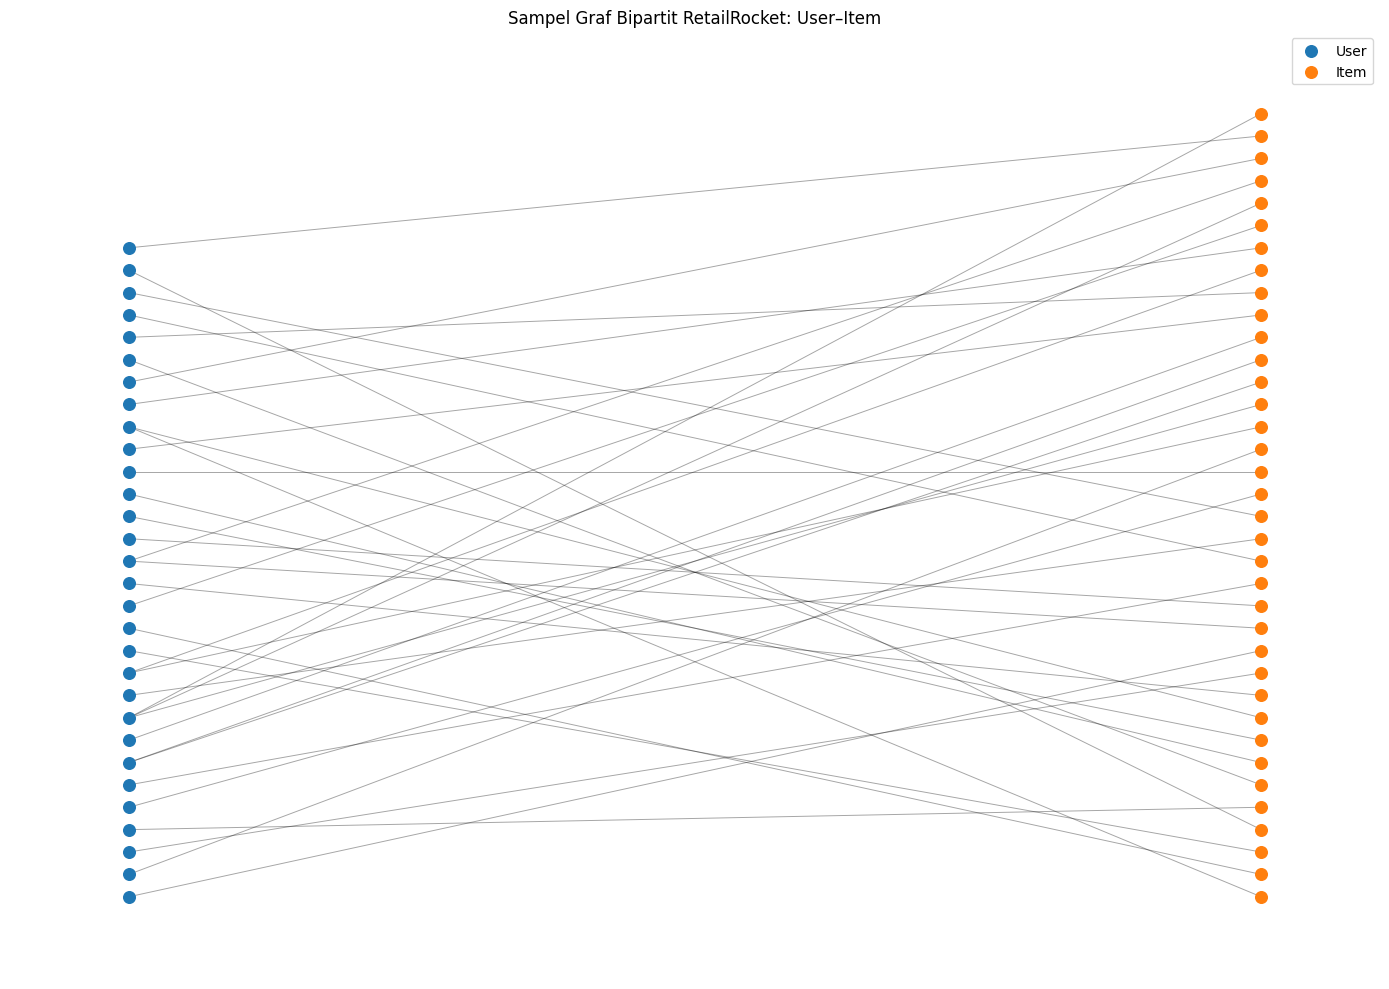

Jumlah simpul pada graf sampel: 66
Jumlah edge pada graf sampel: 36


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Visualisasi sampel graf bipartit User–Item.
# Hanya membaca matriks X_ui yang sudah dibuat.

rng = np.random.default_rng(42)

# Ambil maksimal 30 user secara acak
n_sample_users = min(30, X_ui.shape[0])
sample_user_idx = np.sort(
    rng.choice(X_ui.shape[0], size=n_sample_users, replace=False)
)

# Ambil item yang berinteraksi dengan user sampel
sample_matrix = X_ui[sample_user_idx]
sample_item_idx = np.unique(sample_matrix.indices)

# Batasi jumlah item agar visualisasi tetap terbaca
MAX_ITEMS = 40
if len(sample_item_idx) > MAX_ITEMS:
    sample_item_idx = np.sort(
        rng.choice(sample_item_idx, size=MAX_ITEMS, replace=False)
    )

# Bentuk graf bipartit sampel
G_sample = nx.Graph()

for u_idx in sample_user_idx:
    G_sample.add_node(
        f"U{int(user_ids[u_idx])}",
        node_type="User",
        bipartite=0
    )

for i_idx in sample_item_idx:
    G_sample.add_node(
        f"I{int(item_ids[i_idx])}",
        node_type="Item",
        bipartite=1
    )

# Tambahkan edge hanya untuk pasangan yang ada pada matriks
sample_items_set = set(sample_item_idx)

for u_idx in sample_user_idx:
    row = X_ui.getrow(u_idx)
    for i_idx in row.indices:
        if i_idx in sample_items_set:
            G_sample.add_edge(
                f"U{int(user_ids[u_idx])}",
                f"I{int(item_ids[i_idx])}"
            )

# Atur posisi User dan Item pada dua sisi
user_nodes = [
    n for n, d in G_sample.nodes(data=True)
    if d["node_type"] == "User"
]
item_nodes = [
    n for n, d in G_sample.nodes(data=True)
    if d["node_type"] == "Item"
]

pos = {}
for j, node in enumerate(user_nodes):
    pos[node] = (0, j)

for j, node in enumerate(item_nodes):
    pos[node] = (1, j)

plt.figure(figsize=(14, 10))
nx.draw_networkx_nodes(
    G_sample, pos,
    nodelist=user_nodes,
    node_size=70,
    node_color="tab:blue",
    label="User"
)
nx.draw_networkx_nodes(
    G_sample, pos,
    nodelist=item_nodes,
    node_size=70,
    node_color="tab:orange",
    label="Item"
)
nx.draw_networkx_edges(
    G_sample, pos,
    alpha=0.35,
    width=0.7
)

plt.title("Sampel Graf Bipartit RetailRocket: User–Item")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul pada graf sampel:", G_sample.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_sample.number_of_edges())


=== PROYEKSI USER–USER ===
Jumlah simpul       : 30
Jumlah edge         : 0
Kepadatan graf      : 0.000000
Jumlah komponen     : 30
Rata-rata degree    : 0.00
Median degree       : 0.00
Degree maksimum     : 0

=== PROYEKSI ITEM–ITEM ===
Jumlah simpul       : 36
Jumlah edge         : 7
Kepadatan graf      : 0.011111
Jumlah komponen     : 30
Rata-rata degree    : 0.39
Median degree       : 0.00
Degree maksimum     : 2


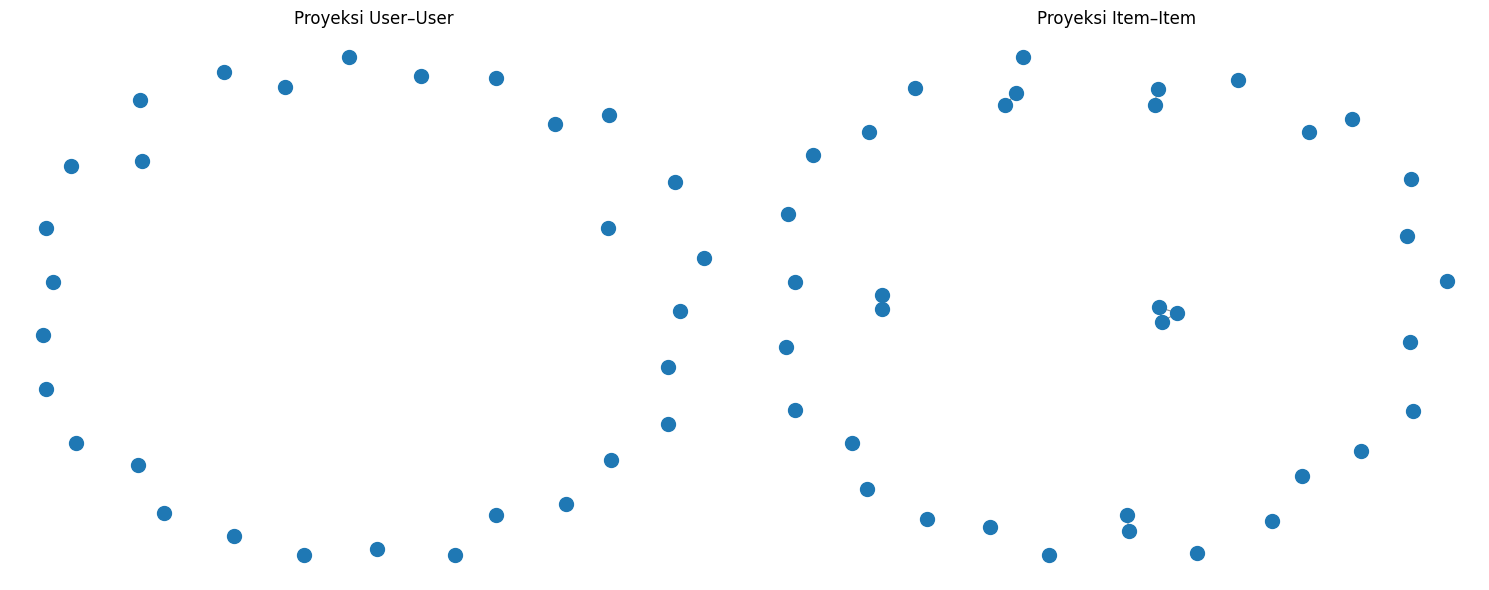

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 1. Bentuk proyeksi berdasarkan graf bipartit sampel
G_user_proj = nx.bipartite.weighted_projected_graph(
    G_sample, user_nodes
)

G_item_proj = nx.bipartite.weighted_projected_graph(
    G_sample, item_nodes
)

# 2. Ringkasan karakteristik proyeksi
def ringkasan_proyeksi(nama, G):
    degrees = np.array([d for _, d in G.degree()])

    print(f"\n=== {nama} ===")
    print(f"Jumlah simpul       : {G.number_of_nodes():,}")
    print(f"Jumlah edge         : {G.number_of_edges():,}")
    print(f"Kepadatan graf      : {nx.density(G):.6f}")
    print(f"Jumlah komponen     : {nx.number_connected_components(G):,}")
    print(f"Rata-rata degree    : {degrees.mean():.2f}" if len(degrees) else "Rata-rata degree    : 0")
    print(f"Median degree       : {np.median(degrees):.2f}" if len(degrees) else "Median degree       : 0")
    print(f"Degree maksimum     : {degrees.max():,}" if len(degrees) else "Degree maksimum     : 0")

ringkasan_proyeksi("PROYEKSI USER–USER", G_user_proj)
ringkasan_proyeksi("PROYEKSI ITEM–ITEM", G_item_proj)

# 3. Visualisasikan kedua proyeksi sampel
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, G, judul in [
    (axes[0], G_user_proj, "Proyeksi User–User"),
    (axes[1], G_item_proj, "Proyeksi Item–Item")
]:
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=100
    )
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        alpha=0.45,
        width=0.8
    )

    ax.set_title(judul)
    ax.axis("off")

plt.tight_layout()
plt.show()

Graf bipartit sampel:
Simpul: 70
Edge: 40

User–User
Simpul: 30
Edge: 0
Kepadatan: 0
Komponen: 30

Item–Item
Simpul: 40
Edge: 26
Kepadatan: 0.033333
Komponen: 22


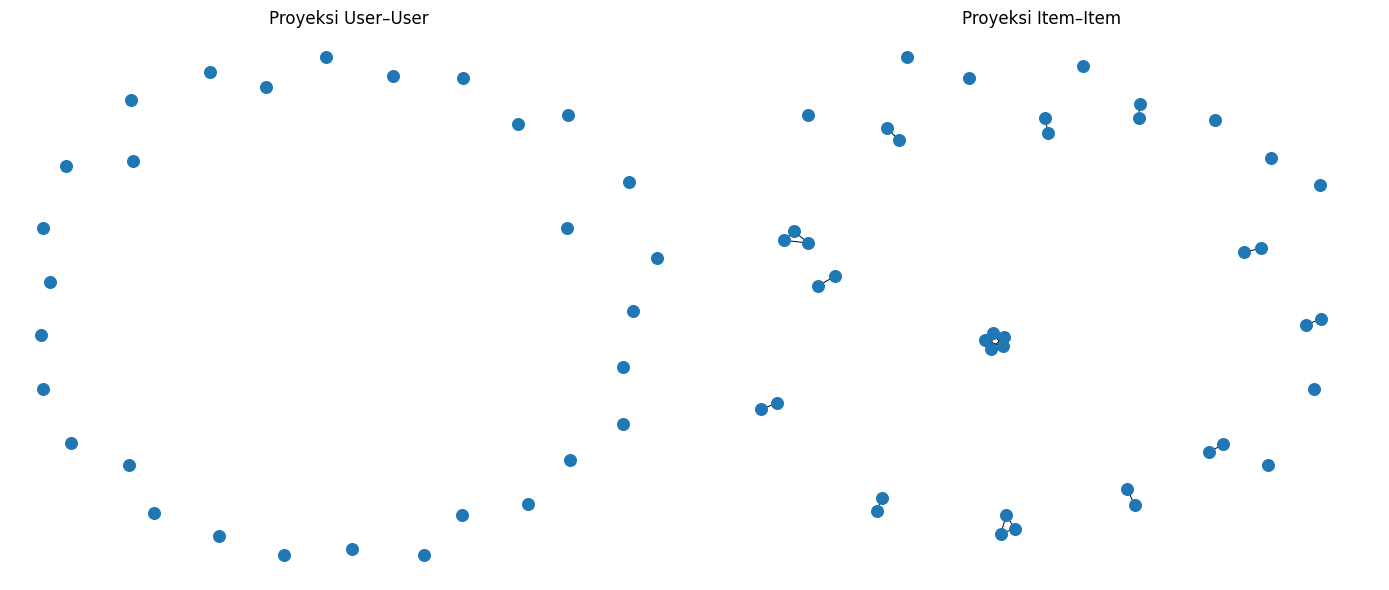

In [ ]:
# Perbaikan sampel untuk visualisasi proyeksi.
# X_ui, user_ids, item_ids sudah tersedia dari langkah sebelumnya.

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# 1. Ambil 200 user kandidat secara acak agar proses tetap ringan
rng = np.random.default_rng(42)
candidate_count = min(200, X_ui.shape[0])

candidate_users = rng.choice(
    X_ui.shape[0],
    size=candidate_count,
    replace=False
)

# Pilih 30 user dengan jumlah item unik terbanyak dari kandidat
candidate_degrees = np.asarray(
    X_ui[candidate_users].getnnz(axis=1)
).ravel()

top_positions = np.argsort(candidate_degrees)[-30:]
selected_users = candidate_users[top_positions]

# 2. Hitung item yang terhubung dengan user terpilih
selected_user_matrix = X_ui[selected_users]
item_frequency = np.asarray(
    selected_user_matrix.sum(axis=0)
).ravel()

# Ambil maksimal 40 item dengan frekuensi tertinggi
connected_items = np.flatnonzero(item_frequency > 0)
max_items = min(40, len(connected_items))

selected_items = connected_items[
    np.argsort(item_frequency[connected_items])[-max_items:]
]

# 3. Bangun graf bipartit sampel
G_sample2 = nx.Graph()

for u_idx in selected_users:
    G_sample2.add_node(
        f"U{int(user_ids[u_idx])}",
        node_type="User"
    )

for i_idx in selected_items:
    G_sample2.add_node(
        f"I{int(item_ids[i_idx])}",
        node_type="Item"
    )

selected_item_set = set(selected_items)

for u_idx in selected_users:
    row = X_ui.getrow(u_idx)
    for i_idx in row.indices:
        if i_idx in selected_item_set:
            G_sample2.add_edge(
                f"U{int(user_ids[u_idx])}",
                f"I{int(item_ids[i_idx])}"
            )

# 4. Bentuk proyeksi dari sampel yang diperbaiki
users2 = [
    n for n, d in G_sample2.nodes(data=True)
    if d["node_type"] == "User"
]
items2 = [
    n for n, d in G_sample2.nodes(data=True)
    if d["node_type"] == "Item"
]

G_user_proj2 = nx.bipartite.weighted_projected_graph(
    G_sample2, users2
)
G_item_proj2 = nx.bipartite.weighted_projected_graph(
    G_sample2, items2
)

# 5. Tampilkan hasil
print("Graf bipartit sampel:")
print("Simpul:", G_sample2.number_of_nodes())
print("Edge:", G_sample2.number_of_edges())

for name, G in [
    ("User–User", G_user_proj2),
    ("Item–Item", G_item_proj2)
]:
    print(f"\n{name}")
    print("Simpul:", G.number_of_nodes())
    print("Edge:", G.number_of_edges())
    print("Kepadatan:", round(nx.density(G), 6))
    print("Komponen:", nx.number_connected_components(G))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, G, title in [
    (axes[0], G_user_proj2, "Proyeksi User–User"),
    (axes[1], G_item_proj2, "Proyeksi Item–Item")
]:
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx(
        G, pos, ax=ax,
        with_labels=False,
        node_size=70,
        width=0.7
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np
from sklearn.neighbors import NearestNeighbors

# Benchmark terbatas pada sejumlah anchor, bukan seluruh graf.
# Tujuannya membandingkan biaya pencarian tetangga pada kedua representasi.

def benchmark_knn(X, nama, n_anchors=20, k=5):
    n_samples = X.shape[0]
    if n_samples <= k:
        print(f"{nama}: jumlah objek tidak cukup untuk k={k}")
        return None

    rng = np.random.default_rng(42)
    anchors = rng.choice(
        n_samples,
        size=min(n_anchors, n_samples),
        replace=False
    )

    model = NearestNeighbors(
        n_neighbors=k + 1,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    start_fit = time.perf_counter()
    model.fit(X)
    fit_seconds = time.perf_counter() - start_fit

    start_query = time.perf_counter()
    model.kneighbors(X[anchors], return_distance=True)
    query_seconds = time.perf_counter() - start_query

    result = {
        "nama": nama,
        "jumlah_objek": X.shape[0],
        "dimensi_vektor": X.shape[1],
        "fit_detik": fit_seconds,
        "query_anchors": len(anchors),
        "query_detik": query_seconds,
        "query_per_anchor_ms": query_seconds / len(anchors) * 1000
    }

    print(f"\n{nama}")
    print(f"Jumlah objek            : {result['jumlah_objek']:,}")
    print(f"Dimensi tiap vektor     : {result['dimensi_vektor']:,}")
    print(f"Waktu fit               : {fit_seconds:.3f} detik")
    print(f"Waktu query {len(anchors)} anchor: {query_seconds:.3f} detik")
    print(f"Waktu per anchor        : {result['query_per_anchor_ms']:.2f} ms")

    return result

hasil_user = benchmark_knn(X_ui, "User–User", n_anchors=20, k=5)
hasil_item = benchmark_knn(X_iu, "Item–Item", n_anchors=20, k=5)


User–User
Jumlah objek            : 313,832
Dimensi tiap vektor     : 117,317
Waktu fit               : 0.014 detik
Waktu query 20 anchor: 0.515 detik
Waktu per anchor        : 25.77 ms

Item–Item
Jumlah objek            : 117,317
Dimensi tiap vektor     : 313,832
Waktu fit               : 0.047 detik
Waktu query 20 anchor: 0.189 detik
Waktu per anchor        : 9.46 ms


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

def karakteristik_vsm(nama, X):
    interaksi_per_objek = np.diff(X.indptr)
    total_kemungkinan = X.shape[0] * X.shape[1]

    return {
        "VSM": nama,
        "Shape": f"{X.shape[0]:,} × {X.shape[1]:,}",
        "Jumlah objek": X.shape[0],
        "Dimensi fitur": X.shape[1],
        "Nonzero": X.nnz,
        "Rata-rata interaksi": round(interaksi_per_objek.mean(), 2),
        "Median interaksi": int(np.median(interaksi_per_objek)),
        "Maksimum interaksi": int(interaksi_per_objek.max()),
        "Sparsity (%)": round(
            (1 - X.nnz / total_kemungkinan) * 100, 6
        )
    }

hasil_vsm = pd.DataFrame([
    karakteristik_vsm("User", X_ui),
    karakteristik_vsm("Item", X_iu)
])

display(hasil_vsm)

,VSM,Shape,Jumlah objek,Dimensi fitur,Nonzero,Rata-rata interaksi,Median interaksi,Maksimum interaksi,Sparsity (%)
0,User,"313,832 × 117,317",313832,117317,471258,1.50,1,1031,99.99872
1,Item,"117,317 × 313,832",117317,313832,471258,4.02,2,1022,99.99872


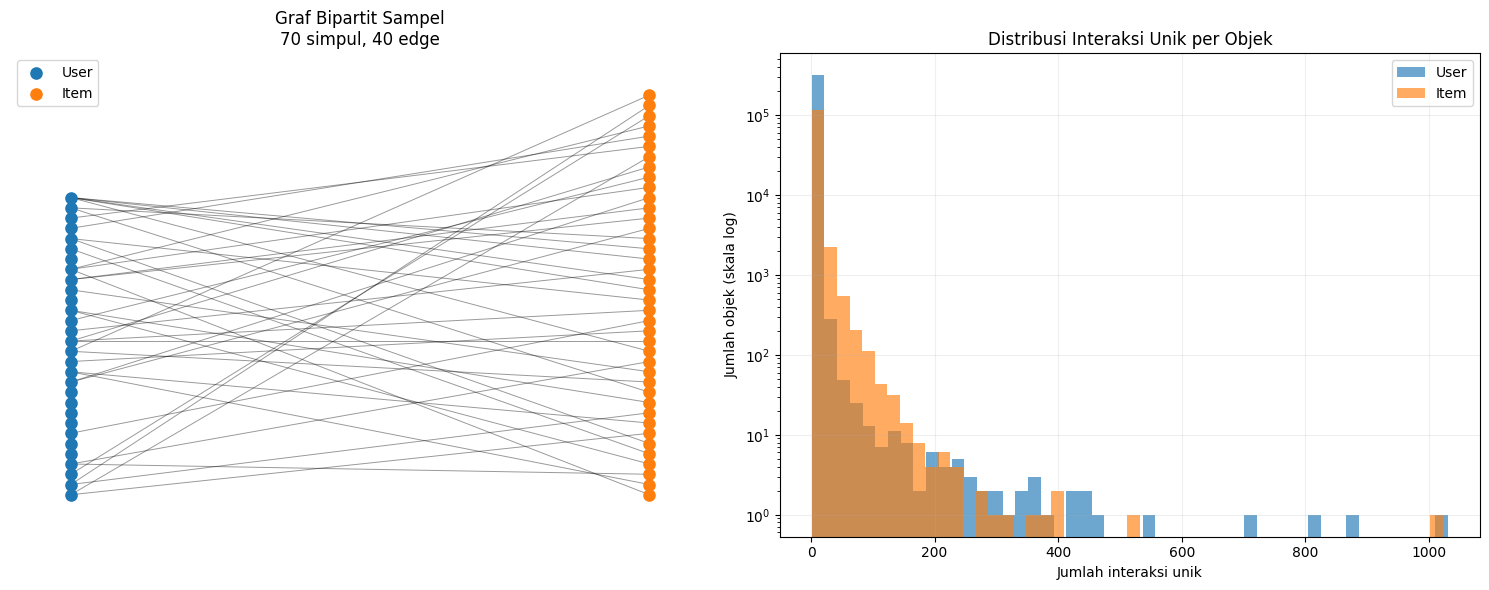

In [ ]:
# Graf sampel yang sudah ada: G_sample2
# Matriks training yang sudah ada: X_ui dan X_iu

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PANEL 1: Graf bipartit User–Item
user_nodes = [
    n for n, d in G_sample2.nodes(data=True)
    if d["node_type"] == "User"
]
item_nodes = [
    n for n, d in G_sample2.nodes(data=True)
    if d["node_type"] == "Item"
]

pos = {}
for idx, node in enumerate(user_nodes):
    pos[node] = (0, idx)
for idx, node in enumerate(item_nodes):
    pos[node] = (1, idx)

nx.draw_networkx_nodes(
    G_sample2, pos, nodelist=user_nodes,
    node_color="tab:blue", node_size=65, ax=axes[0],
    label="User"
)
nx.draw_networkx_nodes(
    G_sample2, pos, nodelist=item_nodes,
    node_color="tab:orange", node_size=65, ax=axes[0],
    label="Item"
)
nx.draw_networkx_edges(
    G_sample2, pos, ax=axes[0],
    alpha=0.4, width=0.7
)

axes[0].set_title(
    f"Graf Bipartit Sampel\n"
    f"{G_sample2.number_of_nodes()} simpul, "
    f"{G_sample2.number_of_edges()} edge"
)
axes[0].legend()
axes[0].axis("off")

# PANEL 2: Distribusi jumlah interaksi unik
user_degree = np.diff(X_ui.indptr)
item_degree = np.diff(X_iu.indptr)

axes[1].hist(
    user_degree, bins=50, alpha=0.65,
    label="User", log=True
)
axes[1].hist(
    item_degree, bins=50, alpha=0.65,
    label="Item", log=True
)
axes[1].set_title("Distribusi Interaksi Unik per Objek")
axes[1].set_xlabel("Jumlah interaksi unik")
axes[1].set_ylabel("Jumlah objek (skala log)")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## *2.2 Analytics*
#### 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

#### 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

(b) NDCG@5

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# 1. Hitung jumlah visitor unik per item
item_interaction_counts = np.diff(X_iu.indptr)

# Pilih item dengan interaksi terbanyak sebagai anchor
anchor_idx = int(np.argmax(item_interaction_counts))
anchor_item_id = int(item_ids[anchor_idx])

print("=== ITEM ACUAN ===")
print(f"Item ID               : {anchor_item_id}")
print(f"Jumlah visitor unik   : {item_interaction_counts[anchor_idx]:,}")

# 2. Hitung cosine similarity anchor terhadap semua item
# Output hanya satu baris similarity, bukan matriks penuh.
anchor_vector = X_iu[anchor_idx]
similarity_scores = cosine_similarity(
    anchor_vector,
    X_iu
).ravel()

# 3. Keluarkan anchor dari hasil, supaya tidak merekomendasikan dirinya sendiri
similarity_scores[anchor_idx] = -1

# Ambil lima item dengan similarity tertinggi
top_indices = np.argsort(similarity_scores)[-5:][::-1]

# 4. Susun hasil
results = []

for rank, idx in enumerate(top_indices, start=1):
    shared_visitors = int(
        anchor_vector.multiply(X_iu[idx]).nnz
    )

    results.append({
        "Rank": rank,
        "Anchor Item": anchor_item_id,
        "Similar Item": int(item_ids[idx]),
        "Cosine Similarity": float(similarity_scores[idx]),
        "Shared Visitors": shared_visitors,
        "Similar Item Visitor Count": int(item_interaction_counts[idx])
    })

similarity_results = pd.DataFrame(results)

print("\n=== TOP 5 ITEM PALING MIRIP ===")
display(similarity_results)

=== ITEM ACUAN ===
Item ID               : 5411
Jumlah visitor unik   : 1,022

=== TOP 5 ITEM PALING MIRIP ===


,Rank,Anchor Item,Similar Item,Cosine Similarity,Shared Visitors,Similar Item Visitor Count
0,1,5411,33030,0.181815,50,74
1,2,5411,358234,0.102162,16,24
2,3,5411,33956,0.100036,15,22
3,4,5411,375492,0.074775,20,70
4,5,5411,89143,0.064586,9,19


In [ ]:
# Menampilkan ulang hasil yang sudah dihitung, tanpa mengubah data.

display(
    similarity_results[
        [
            "Rank",
            "Anchor Item",
            "Similar Item",
            "Cosine Similarity",
            "Shared Visitors",
            "Similar Item Visitor Count"
        ]
    ].to_string(index=False)
)

' Rank  Anchor Item  Similar Item  Cosine Similarity  Shared Visitors  Similar Item Visitor Count\n    1         5411         33030           0.181815               50                          74\n    2         5411        358234           0.102162               16                          24\n    3         5411         33956           0.100036               15                          22\n    4         5411        375492           0.074775               20                          70\n    5         5411         89143           0.064586                9                          19'

In [ ]:
query = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemid AS Anchor_Item,
    b.itemid AS Similar_Item,
    r.score AS Cosine_Similarity
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    result = session.run(query)
    records = [record.data() for record in result]

display(pd.DataFrame(records))

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=19, offset=19>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 19, 'line': 2, 'column': 19}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)\nRETURN\n    a.itemid AS Anchor_Item,\n    b.itemid AS Similar_Item,\n    r.score AS Cosine_Similarity\nORDER BY r.score DESC\nLIMIT 5\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key do

""


In [ ]:
query = """
MATCH (i:Item)
RETURN keys(i) AS Property_Names, i AS Sample_Item
LIMIT 3
"""

with driver.session(database=DATABASE) as session:
    records = [record.data() for record in session.run(query)]

display(pd.DataFrame(records))

,Property_Names,Sample_Item
0,[itemId],{'itemId': 355908}
1,[itemId],{'itemId': 248676}
2,[itemId],{'itemId': 318965}


In [ ]:
# Siapkan lima hasil similarity dari perhitungan Python
similarity_rows = similarity_results.to_dict(orient="records")

query = """
UNWIND $rows AS row

MATCH (a:Item {itemId: row.`Anchor Item`})
MATCH (b:Item {itemId: row.`Similar Item`})

MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = row.`Cosine Similarity`,
    r.sharedVisitors = row.`Shared Visitors`,
    r.similarItemVisitorCount = row.`Similar Item Visitor Count`,
    r.fold = 'P1_training'

RETURN
    a.itemId AS Anchor_Item,
    b.itemId AS Similar_Item,
    r.score AS Cosine_Similarity,
    r.sharedVisitors AS Shared_Visitors
ORDER BY Cosine_Similarity DESC
"""

with driver.session(database=DATABASE) as session:
    records = [
        record.data()
        for record in session.run(query, rows=similarity_rows)
    ]

display(pd.DataFrame(records))

,Anchor_Item,Similar_Item,Cosine_Similarity,Shared_Visitors
0,5411,33030,0.181815,50
1,5411,358234,0.102162,16
2,5411,33956,0.100036,15
3,5411,375492,0.074775,20
4,5411,89143,0.064586,9


In [ ]:
query = """
MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS Anchor_Item,
    b.itemId AS Similar_Item,
    r.score AS Cosine_Similarity,
    r.sharedVisitors AS Shared_Visitors
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    records = [record.data() for record in session.run(query)]

display(pd.DataFrame(records))

,Anchor_Item,Similar_Item,Cosine_Similarity,Shared_Visitors
0,5411,33030,0.181815,50
1,5411,358234,0.102162,16
2,5411,33956,0.100036,15
3,5411,375492,0.074775,20
4,5411,89143,0.064586,9


In [ ]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Baca data untuk memisahkan interaksi training dan testing
df_events = pd.read_csv(
    CSV_PATH,
    usecols=["visitorid", "itemid", "event", "fold"]
)

df_p2 = df_events[df_events["fold"] == "P2_testing"]

# Pemetaan ID ke indeks matriks
user_to_idx = {int(uid): idx for idx, uid in enumerate(user_ids)}
item_to_idx = {int(iid): idx for idx, iid in enumerate(item_ids)}
item_catalog = set(item_to_idx.keys())

# Item yang berinteraksi dengan user pada P2
p2_items_by_user = (
    df_p2.groupby("visitorid")["itemid"]
    .agg(lambda x: set(x.astype(int)))
    .to_dict()
)

# Pilih user yang punya item relevan di P2,
# tetapi item tersebut belum pernah diinteraksikan pada P1
eligible_users = []

for uid, test_items in sorted(p2_items_by_user.items()):
    uid = int(uid)

    if uid not in user_to_idx:
        continue

    user_idx = user_to_idx[uid]
    seen_train = set(item_ids[X_ui[user_idx].indices].astype(int))

    relevant_items = (test_items & item_catalog) - seen_train

    if relevant_items:
        eligible_users.append((uid, relevant_items))

if not eligible_users:
    raise ValueError("Tidak ditemukan user yang memenuhi kriteria evaluasi.")

# Pemilihan user secara acak, tetapi hasilnya reproducible
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Acak urutan kandidat user yang sudah memenuhi syarat evaluasi P2
candidate_users = rng.permutation(len(eligible_users))

selected_result = None

for pos in candidate_users:
    uid, relevant_items = eligible_users[pos]
    uid = int(uid)
    user_idx = user_to_idx[uid]

    # Cari 5 tetangga terdekat dari data P1
    distances, indices = knn.kneighbors(
        X_ui[user_idx],
        n_neighbors=6
    )

    neighbors = [
        (idx, 1.0 - distance)
        for idx, distance in zip(indices[0], distances[0])
        if idx != user_idx
    ][:5]

    if len(neighbors) < 5:
        continue

    neighbor_indices = np.array(
        [idx for idx, _ in neighbors], dtype=int
    )
    neighbor_similarities = np.array(
        [sim for _, sim in neighbors], dtype=float
    )

    # Hitung skor kandidat berdasarkan interaksi tetangga
    scores = np.asarray(
        X_ui[neighbor_indices].T @ neighbor_similarities
    ).ravel()

    # Hilangkan item yang sudah pernah dilihat user pada P1
    seen_indices = X_ui[user_idx].indices
    scores[seen_indices] = -np.inf

    # Kandidat harus punya skor positif
    candidate_indices = np.flatnonzero(
        np.isfinite(scores) & (scores > 0)
    )

    if len(candidate_indices) >= 5:
        ranked_indices = candidate_indices[
            np.argsort(scores[candidate_indices])[::-1]
        ]

        selected_result = (
            uid,
            relevant_items,
            ranked_indices[:5],
            scores
        )
        break

if selected_result is None:
    raise ValueError(
        "Tidak ditemukan user dengan minimal 5 kandidat. "
        "Kita perlu meninjau strategi rekomendasi."
    )

selected_user_id, test_relevant_items, top5_indices, scores = selected_result

recommendations = pd.DataFrame({
    "Rank": np.arange(1, 6),
    "Item_ID": item_ids[top5_indices].astype(int),
    "Score": scores[top5_indices]
})

print("User terpilih:", selected_user_id)
print("Random seed:", RANDOM_SEED)
print("Jumlah item relevan pada P2:", len(test_relevant_items))

print("\nLima rekomendasi untuk evaluasi:")
display(recommendations)

print("\nTiga item rekomendasi sesuai instruksi:")
display(recommendations.head(3))

User terpilih: 951502
Random seed: 42
Jumlah item relevan pada P2: 1

Lima rekomendasi untuk evaluasi:


,Rank,Item_ID,Score
0,1,162411,0.700199
1,2,371985,0.390360
2,3,138523,0.390360
3,4,457181,0.309839
4,5,164027,0.309839



Tiga item rekomendasi sesuai instruksi:


,Rank,Item_ID,Score
0,1,162411,0.700199
1,2,371985,0.390360
2,3,138523,0.390360


In [ ]:
# Item yang direkomendasikan dalam top 5
recommended_items = recommendations["Item_ID"].tolist()

# Relevansi biner berdasarkan item yang muncul pada P2
relevance = np.array([
    int(item_id in test_relevant_items)
    for item_id in recommended_items
])

# Hit@5: apakah minimal satu item relevan muncul di top 5?
hit_at_5 = int(relevance.sum() > 0)

# DCG@5: posisi item relevan memengaruhi nilai
ranks = np.arange(1, len(relevance) + 1)
discounts = np.log2(ranks + 1)

dcg_at_5 = np.sum(relevance / discounts)

# IDCG: DCG ideal jika item relevan ditempatkan paling atas
ideal_relevance = np.sort(relevance)[::-1]
idcg_at_5 = np.sum(ideal_relevance / discounts)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("User ID:", selected_user_id)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(float(ndcg_at_5), 4))
print("Item relevan pada top 5:", int(relevance.sum()))

User ID: 951502
Hit@5: 0
NDCG@5: 0.0
Item relevan pada top 5: 0


In [ ]:
print("User ID:", selected_user_id)

print("\nItem relevan pada P2 yang belum muncul di P1:")
print(sorted(test_relevant_items))

print("\nItem rekomendasi Top-5:")
print(recommendations["Item_ID"].tolist())

print("\nIrisan rekomendasi dengan item relevan:")
print(
    sorted(
        set(recommendations["Item_ID"].astype(int))
        & test_relevant_items
    )
)

User ID: 951502

Item relevan pada P2 yang belum muncul di P1:
[264152]

Item rekomendasi Top-5:
[162411, 371985, 138523, 457181, 164027]

Irisan rekomendasi dengan item relevan:
[]
